In [1]:
import numpy as np
import matplotlib.pyplot as plt
#import skrf as rf
from src.fit_methods.dcm import DCM
from src.resonator import Resonator
#from example_data_dcm import freqs, S21, Qtot
from plotting import plotres
from src.utils import remove_delay, find_circle
import lmfit
from matplotlib.patches import Circle

In [2]:
from pathlib import Path
# Paths to your data
freq_path = Path('examples/frequencies.npy')  # .npy or .csv
s21_path  = Path('examples/S21_RAW.npy')  # .npy or .csv

# Choose format of S21 if not complex npy
# Options: 'complex_npy', 'reim_csv', 'magphase_deg_csv'
s21_format = 'complex_npy'

# Frequency units of your input file; converted to GHz internally
# Options: 'GHz', 'Hz', 'MHz', 'kHz'
freq_units = 'GHz'

# Choose fitting method: 'dcm' for hanger (S21), 'reflection' for S11
method = 'dcm'



In [3]:
def load_array(path: Path) -> np.ndarray:
    path = Path(path)
    if path.suffix.lower() == '.npy':
        return np.load(path)
    # CSV/TXT fallback
    return np.genfromtxt(path, delimiter=',', dtype=float)

def parse_s21(data: np.ndarray, fmt: str) -> np.ndarray:
    fmt = fmt.lower()
    if fmt == 'complex_npy':
        if not np.iscomplexobj(data):
            raise ValueError('Expected complex dtype in npy for complex_npy format.')
        return data.astype(np.complex128)
    if fmt == 'reim_csv':
        if data.ndim == 1 or data.shape[1] < 2:
            raise ValueError('reim_csv expects 2 columns: re,im')
        return (data[:, 0] + 1j * data[:, 1]).astype(np.complex128)
    if fmt == 'magphase_deg_csv':
        if data.ndim == 1 or data.shape[1] < 2:
            raise ValueError('magphase_deg_csv expects 2 columns: mag,phase_deg')
        mag = data[:, 0]
        ph = np.deg2rad(data[:, 1])
        return (mag * np.exp(1j * ph)).astype(np.complex128)
    raise ValueError(f'Unknown s21-format: {fmt}')

def convert_freq_to_ghz(f: np.ndarray, units: str) -> np.ndarray:
    units = units.lower()
    scale = {'hz': 1e-9, 'khz': 1e-6, 'mhz': 1e-3, 'ghz': 1.0}
    if units not in scale:
        raise ValueError(f'Unsupported units: {units}')
    f_ghz = f * scale[units]
    return f_ghz.squeeze()


In [4]:
# Load frequency and S21
freqs_raw = load_array(freq_path).astype(float)
s21_raw = load_array(s21_path)

# Convert frequencies to GHz
freqs = convert_freq_to_ghz(freqs_raw, freq_units)

# Parse S21 according to selected format or auto-detect if possible
if s21_format == 'complex_npy' and s21_raw.ndim > 1:
    # If user selected complex_npy but provided 2-column CSV, try re,im as a convenience
    s21 = parse_s21(s21_raw, 'reim_csv')
else:
    s21 = parse_s21(s21_raw, s21_format)

print(f'freqs shape: {freqs.shape}, dtype: {freqs.dtype}')
print(f's21 shape:   {s21.shape}, dtype: {s21.dtype}, complex: {np.iscomplexobj(s21)}')
assert freqs.shape[0] == s21.shape[0], 'Frequency and S21 lengths must match'

print(freqs)
print(s21)

freqs shape: (5001,), dtype: float64
s21 shape:   (5001,), dtype: complex128, complex: True
[6.907600e+09 6.907606e+09 6.907612e+09 ... 6.937588e+09 6.937594e+09
 6.937600e+09]
[-3.92443056e-05+0.00085789j -2.48980950e-05+0.00085531j
 -4.28911393e-05+0.0008487j  ...  1.73081740e-04+0.00077006j
  2.01071962e-04+0.00077451j  1.63806474e-04+0.00076108j]


In [5]:
from scipy.stats import linregress
#1  Preprocess linear
phase = np.unwrap(np.angle(s21))

# Normalize phase using linear fit
normalize=4
slope, intercept, _, _, _ = linregress(
    np.append(freqs[:normalize], freqs[-normalize:]),
    np.append(phase[:normalize], phase[-normalize:])
)

# Adjust phase to remove cable delay and rotate off-resonant point to (1, 0i)
adjusted_phase = phase - (slope * freqs + intercept)
y_adjusted = np.abs(s21) * np.exp(1j * adjusted_phase)

# Normalize magnitude using linear fit
y_db = 20 * np.log10(np.abs(s21))
mag_slope, mag_intercept, _, _, _ = linregress(
    np.append(freqs[:normalize], freqs[-normalize:]),
    np.append(y_db[:normalize], y_db[-normalize:])
)
adjusted_magnitude = 10 ** ((y_db - (mag_slope * freqs + mag_intercept)) / 20)

s21_preprocessed = adjusted_magnitude * np.exp(1j * adjusted_phase)
print(s21_preprocessed)

[1.00039557+0.00315197j 0.99673501-0.01085774j 0.98985615+0.01293644j ...
 1.002006  +0.00503355j 1.01556691-0.02572233j 0.98820579+0.01902965j]


In [6]:
from src.fit_methods.dcm import DCM
res = Resonator()
res.load_data(fdata = freqs, sdata = s21_preprocessed) #IT SHOULD BE PREPROCESSED
res.set_fitting_strategy(DCM)

# res.fitter.databg = False
res.fitter.preprocess_linear = False
res.fitter.remove_elec_delay = True
res.fitter.preprocess_circle = True
# res.fitter.delay_guess =0

In [8]:
params = res.fit(verbose=True)

Q_guess: 11894.254295532646
initial delay guess: 2.198547730000952e-09
phi (preprocessing): 2.9878040959607794
Q_guess: 12018.152777777777
[[Model]]
    Model(func)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 37
    # data points      = 10002
    # variables        = 4
    chi-square         = 29.3493400
    reduced chi-square = 0.00293552
    Akaike info crit   = -58316.3655
    Bayesian info crit = -58287.5233
    R-squared          = np.complex128(1.985165196899128e+16-6161948856256169j)
[[Variables]]
    Q:    5489.90435 +/- 36.7152837 (0.67%) (init = 12018.15)
    Qc:   6070.99949 +/- 29.1010328 (0.48%) (init = 13465.35)
    f0:   6.9226e+09 +/- 4216.50388 (0.00%) (init = 6.922456e+09)
    phi: -0.11034535 +/- 0.00479341 (4.34%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(f0, phi) = +0.7167
    C(Q, Qc)   = +0.7167


In [9]:
# res.fitter.delay_guess = 0 #if none 
# delay = res.fitter.find_delay(freqs, s21_preprocessed)
# z_data = remove_delay(freqs, s21_preprocessed, delay)
# print(f'delay: {delay}')

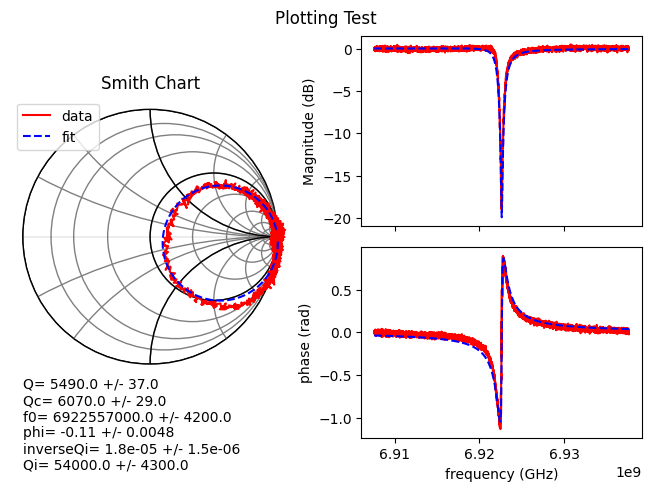

In [10]:
#Begin results plot
fig, ax = plotres.makeSummaryFigure()
plotres.summaryPlot(freqs, s21_preprocessed, color = 'r', label = 'data')
plotres.summaryPlot(freqs, DCM.fit_function(freqs, params), color = 'b', linestyle = 'dashed', label='fit')

#plotres.summaryPlot(freqs, z_data, color = 'green', label = 'delay removed')

#ax['smith'].add_patch(Circle((xc, yc),R, fill = True, color = 'red'))
#plotres.annotateParam(params['Qi'])
#plotres.annotateParam(params['f0'])
#plotres.annotateParam(params['Qc'])
plotres.displayAllParams(params)
fig.suptitle('Plotting Test')
plt.show()

In [23]:
Q = params['Q'].value
Qi = params['Qi'].value
Qc = params['Qc'].value
phi = params['phi'].value
f0 = params['f0'].value
omega0 = 2*np.pi*f0

# Decay rates (angular, rad/s)

In [26]:
kappa_i = omega0 / Qi
kappa_c = omega0 / Qc
kappa = omega0 / Q

print(f"kappa_i :{kappa_i}(rad/s)")
print(f"kappa_c :{kappa_c}(rad/s)")
print(f"kappa:{kappa}(rad/s)")

_2pi=2*np.pi
print(f"kappa_i :{kappa_i/_2pi/1e6}(MHz)")
print(f"kappa_c :{kappa_c/_2pi/1e6}(MHz))")
print(f"kappa:{kappa/_2pi/1e6}(MHz)")



kappa_i :801921.8248423625(rad/s)
kappa_c :7164505.118657969(rad/s)
kappa:7922853.332020887(rad/s)
kappa_i :0.12762982239693507(MHz)
kappa_c :1.1402664044416018(MHz))
kappa:1.2609612711832177(MHz)
